<a href="https://colab.research.google.com/github/baynobu/PCVK-Ganjil-26/blob/main/P9_01_Abdul_Rahman_Hanif_D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modul 9 - Morfologi
## (Erosi, Dilasi, Opening, Closing, Transformasi Top-hat dan Black-hat, Skeleton, Thinning, Thickening)

---

| Keterangan | Detail |
|---|---|
| **Nama** | Abdul Rahman Hanif Darmawan |
| **NIM** | 244107020232 |
| **Kelas** | TI-3G |
| **Absen** | 01 |

## Langkah 1 - Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Langkah 2 - Import Library dan Definisi Path Image

In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

# Definisi path image untuk looping perbandingan
BASE_PATH = '/content/drive/MyDrive/Uni/Internal/Semester 5/PCdVK/'
IMAGES = [
    (BASE_PATH + 'platnomor.jpg', 'Plat Nomor'),
    (BASE_PATH + 'noisy_text.png', 'Noisy Text'),
]

## Langkah 3 - Dilasi Tanpa Library
Buatlah fungsi dilasi serta tampilkan hasil dilasi pada citra dengan Structuring Element Dilasi (SED) berbentuk cross 3 x 3 tanpa menggunakan library morphology dari openCV.

=== Plat Nomor ===


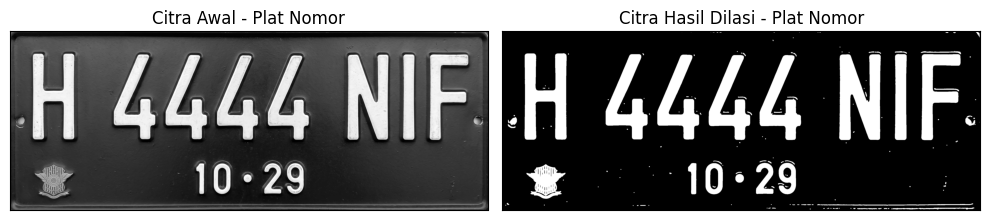

=== Noisy Text ===


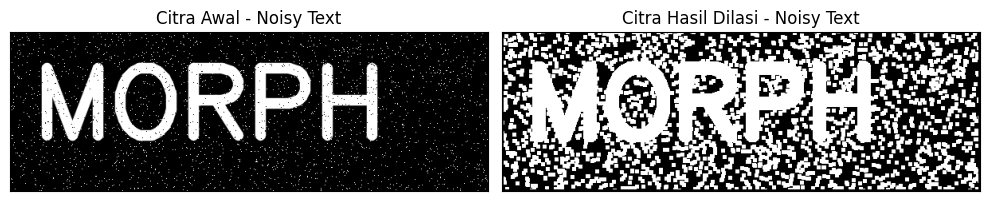

In [3]:
#Dilasi tanpa library

def dilasi_citra(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)

  #Generate structure element dilasi (SED)
  SED= np.ones((w,w), dtype=np.uint8)
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

w=5
for img_path, img_name in IMAGES:
  print(f'=== {img_name} ===')
  img_d= cv2.imread(img_path,0)
  ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
  imgD = dilasi_citra(thresh,w)

  plt.figure(figsize=(10,4))
  plt.subplot(121),plt.imshow(img_d,cmap = 'gray')
  plt.title(f'Citra Awal - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(imgD,cmap = 'gray')
  plt.title(f'Citra Hasil Dilasi - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.tight_layout()
  plt.show()

## Langkah 4 - Dilasi Menggunakan Library OpenCV
Buatlah program implementasi operasi dilasi Structuring Element Dilasi (SED) berbentuk cross 3 x 3 dengan menggunakan library morphology dari openCV.

[[1 1 1]
 [1 1 1]
 [1 1 1]]
=== Plat Nomor ===


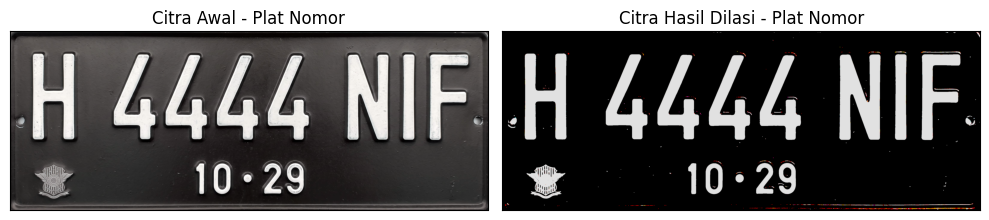

=== Noisy Text ===


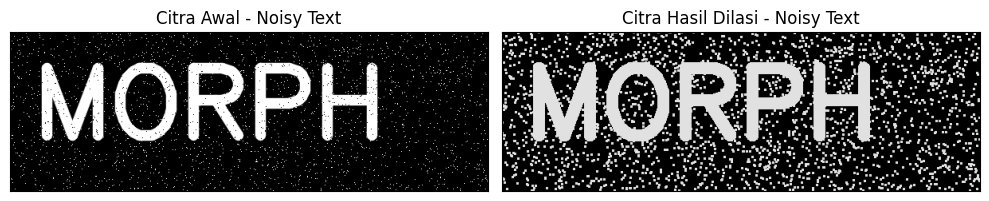

In [4]:
kernel = np.ones((3,3),np.uint16)
print(kernel)

for img_path, img_name in IMAGES:
  print(f'=== {img_name} ===')
  img = cv2.imread(img_path)
  ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
  dilasi = cv2.dilate(thresh,kernel,iterations = 1)

  plt.figure(figsize=(10,4))
  plt.subplot(121),plt.imshow(img),plt.title(f'Citra Awal - {img_name}')
  plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(dilasi),plt.title(f'Citra Hasil Dilasi - {img_name}')
  plt.xticks([]), plt.yticks([])
  plt.tight_layout()
  plt.show()

## Langkah 5 - Erosi Tanpa Library
Buatlah fungsi erosi serta tampilkan hasil erosi pada citra dengan Structuring Element Erosi (SE) berbentuk square 5 x 5 tanpa menggunakan library morphology dari openCV.

=== Plat Nomor ===


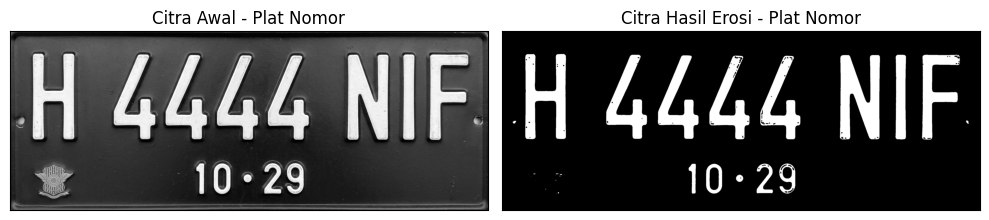

=== Noisy Text ===


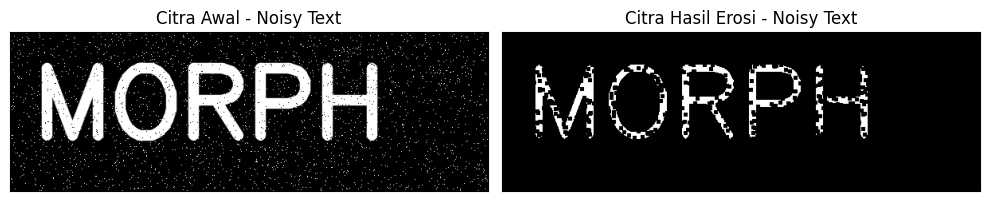

In [5]:
#Erosi Tanpa Library

def erosi_citra(F,k):
  #size image
  m,n= F.shape

  #Generate structure element erosi (SE)
  SE= np.ones((k,k), dtype=np.uint8)
  constant= (k-1)//2

  imgE= np.zeros((m,n), dtype=np.uint8)

  #Proses Erosi
  for i in range(constant, m-constant):
    for j in range(constant,n-constant):
      temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
      product= temp*SE
      imgE[i,j]= np.min(product)

  return imgE

k=5
for img_path, img_name in IMAGES:
  print(f'=== {img_name} ===')
  img_e= cv2.imread(img_path,0)
  ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
  imgE = erosi_citra(thresh1,k)

  plt.figure(figsize=(10,4))
  plt.subplot(121),plt.imshow(img_e,cmap = 'gray')
  plt.title(f'Citra Awal - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(imgE,cmap = 'gray')
  plt.title(f'Citra Hasil Erosi - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.tight_layout()
  plt.show()

## Langkah 6 - Erosi Menggunakan Library OpenCV
Buatlah program implementasi operasi erosi Structuring Element Erosi (SE) berbentuk square 5 x 5 dengan menggunakan library morphology dari openCV.

=== Plat Nomor ===


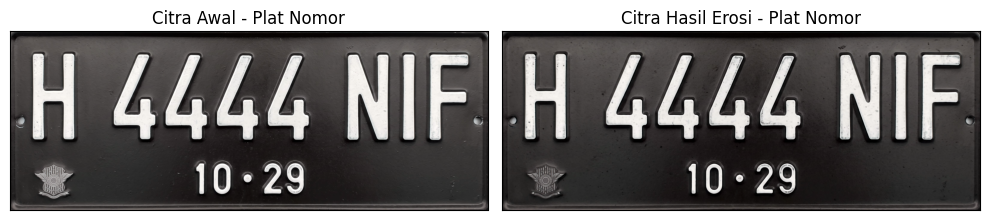

=== Noisy Text ===


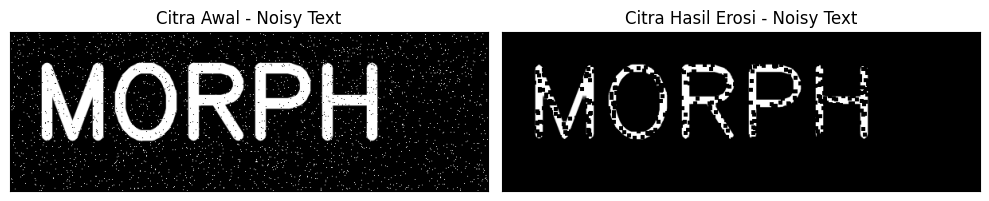

In [6]:
#EROSI LIBRARY
kernel = np.ones((5,5),np.uint8)

for img_path, img_name in IMAGES:
  print(f'=== {img_name} ===')
  img = cv2.imread(img_path)
  erosion = cv2.erode(img,kernel,iterations = 1)

  plt.figure(figsize=(10,4))
  plt.subplot(121),plt.imshow(img),plt.title(f'Citra Awal - {img_name}')
  plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(erosion),plt.title(f'Citra Hasil Erosi - {img_name}')
  plt.xticks([]), plt.yticks([])
  plt.tight_layout()
  plt.show()

## Langkah 7 - Opening Tanpa dan Dengan Library
Buatlah program implementasi operasi opening dengan Structuring Element berbentuk square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV.

=== Opening Tanpa Library - Plat Nomor ===


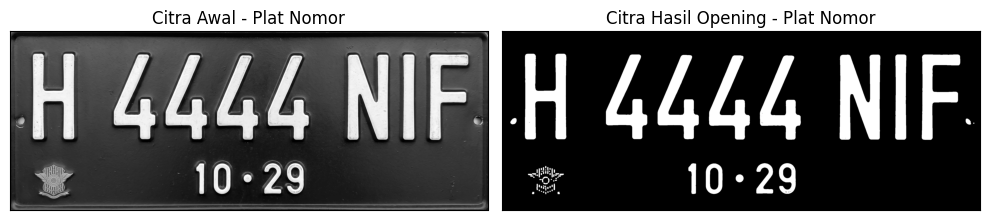

=== Opening Tanpa Library - Noisy Text ===


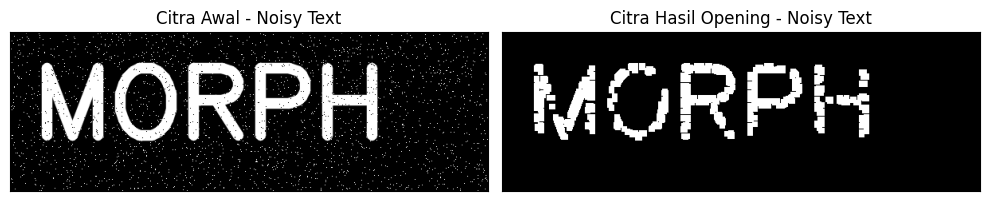

In [7]:
# Operasi Opening Menggunakan tanpa Library Morphology
k=7
for img_path, img_name in IMAGES:
  print(f'=== Opening Tanpa Library - {img_name} ===')
  img_o= cv2.imread(img_path,0)
  reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
  imgO = dilasi_citra(erosi_citra(thresho,k),k)

  plt.figure(figsize=(10,4))
  plt.subplot(121),plt.imshow(img_o,cmap = 'gray')
  plt.title(f'Citra Awal - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(imgO,cmap = 'gray')
  plt.title(f'Citra Hasil Opening - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.tight_layout()
  plt.show()

=== Opening Dengan Library - Plat Nomor ===


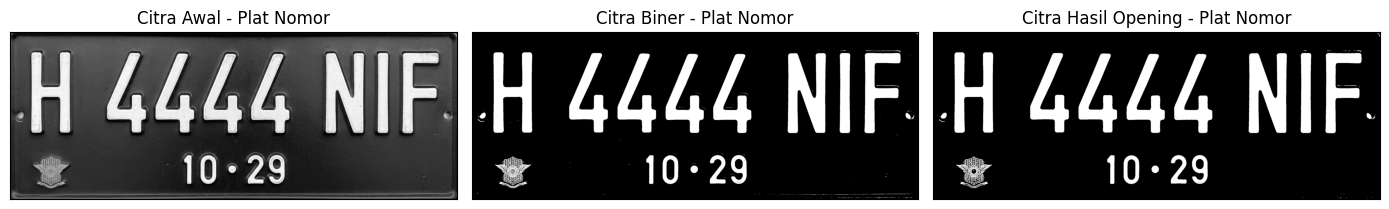

=== Opening Dengan Library - Noisy Text ===


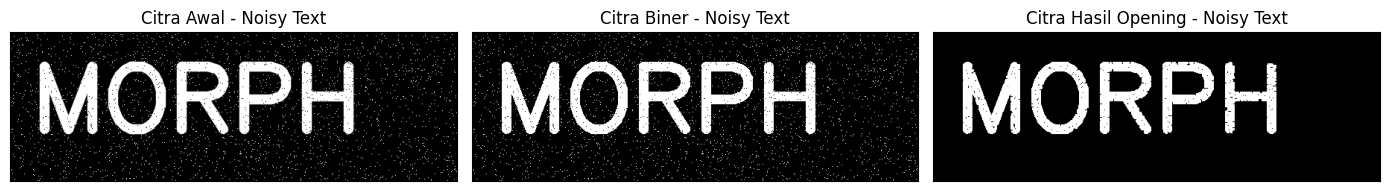

In [8]:
# Operasi Opening Menggunakan Library Morphology
#Dengan Menggunakan Library
kernel = np.ones((3,3),np.uint8)

for img_path, img_name in IMAGES:
  print(f'=== Opening Dengan Library - {img_name} ===')
  img = cv2.imread(img_path,0)
  ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
  openn = cv2.morphologyEx(thresh,cv2.MORPH_OPEN, kernel)

  plt.figure(figsize=(14,4))
  plt.subplot(131),plt.imshow(img,cmap = 'gray')
  plt.title(f'Citra Awal - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
  plt.title(f'Citra Biner - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.subplot(133),plt.imshow(openn,cmap = 'gray')
  plt.title(f'Citra Hasil Opening - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.tight_layout()
  plt.show()

## Langkah 8 - Closing Tanpa dan Dengan Library
Buatlah program implementasi operasi closing dengan Structuring Element berbentuk square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV.

=== Closing Tanpa Library - Plat Nomor ===


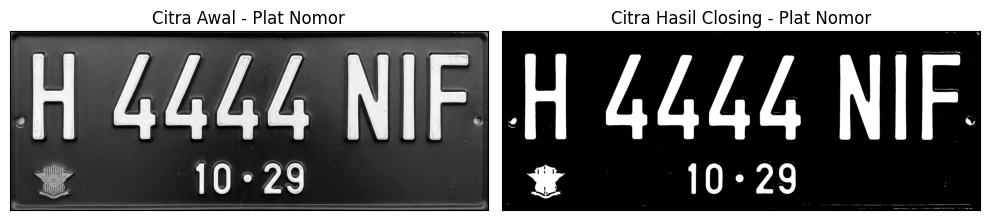

=== Closing Tanpa Library - Noisy Text ===


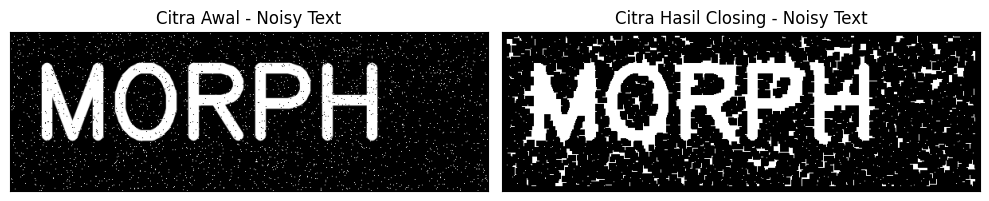

In [9]:
# Operasi Closing tanpa library morphology
k=7
for img_path, img_name in IMAGES:
  print(f'=== Closing Tanpa Library - {img_name} ===')
  img_c= cv2.imread(img_path,0)
  retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
  imgC = erosi_citra(dilasi_citra(threshc,k),k)

  plt.figure(figsize=(10,4))
  plt.subplot(121),plt.imshow(img_c,cmap = 'gray')
  plt.title(f'Citra Awal - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(imgC,cmap = 'gray')
  plt.title(f'Citra Hasil Closing - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.tight_layout()
  plt.show()

=== Closing Dengan Library - Plat Nomor ===


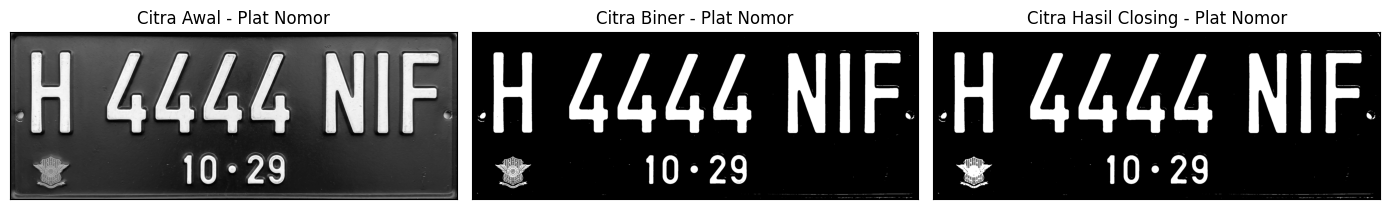

=== Closing Dengan Library - Noisy Text ===


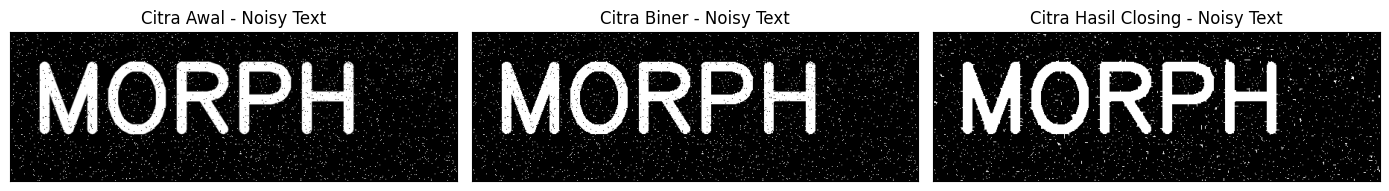

In [10]:
# Operasi Closing dengan library morphology
kernel = np.ones((3,3),np.uint8)

for img_path, img_name in IMAGES:
  print(f'=== Closing Dengan Library - {img_name} ===')
  img = cv2.imread(img_path,0)
  ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
  closs = cv2.morphologyEx(thresh,cv2.MORPH_CLOSE, kernel)

  plt.figure(figsize=(14,4))
  plt.subplot(131),plt.imshow(img,cmap = 'gray')
  plt.title(f'Citra Awal - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
  plt.title(f'Citra Biner - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.subplot(133),plt.imshow(closs,cmap = 'gray')
  plt.title(f'Citra Hasil Closing - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.tight_layout()
  plt.show()

## Langkah 9 - Dilasi dengan SE Cross 3x3 dan 5x5
Buatlah program implementasi operasi dilasi dengan Structuring Element berbentuk Cross 3 x 3 dan 5 x 5.

SED = Cross 3 - Plat Nomor


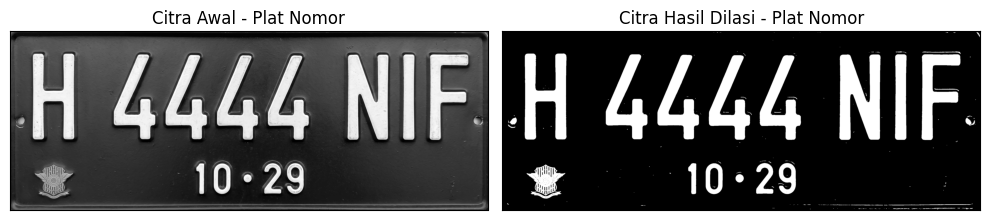

SED = Cross 3 - Noisy Text


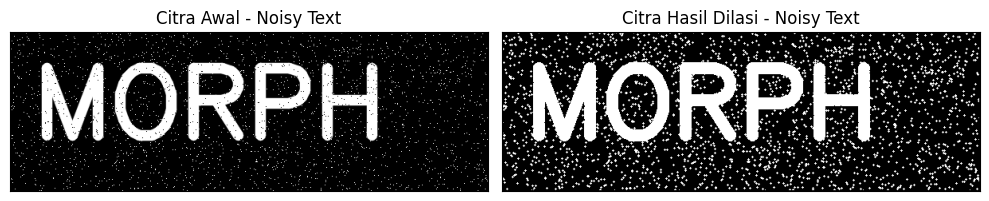

In [11]:
#Dilasi Cross SED 3x3

def dilasi_citra_cross3(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)
  #Generate structure element dilasi (SED)
  SED = np.array([[0, 1, 0],
                [1, 1, 1],
                [0, 1, 0]], dtype = np.uint8)
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

w=3
for img_path, img_name in IMAGES:
  print(f'SED = Cross 3 - {img_name}')
  img_d= cv2.imread(img_path,0)
  ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
  imgD = dilasi_citra_cross3(thresh,w)

  plt.figure(figsize=(10,4))
  plt.subplot(121),plt.imshow(img_d,cmap = 'gray')
  plt.title(f'Citra Awal - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(imgD,cmap = 'gray')
  plt.title(f'Citra Hasil Dilasi - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.tight_layout()
  plt.show()

SED = Cross 5 - Plat Nomor


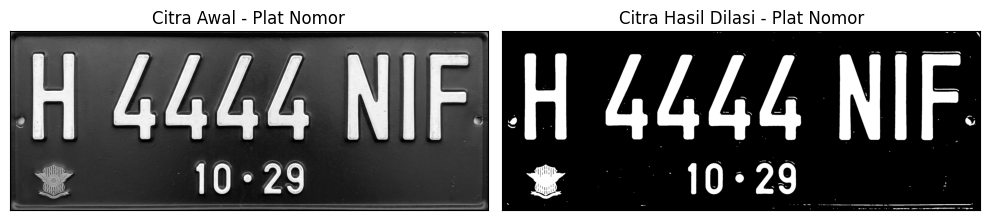

SED = Cross 5 - Noisy Text


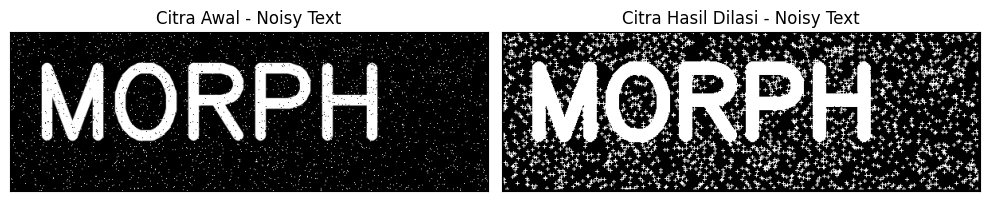

In [12]:
#Dilasi Cross SED 5x5

def dilasi_citra_cross5(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)

  #Generate structure element dilasi (SED)
  SED = np.array([[0, 0, 1, 0, 0],
                [0, 0, 1, 0, 0],
                [1, 1, 1, 1, 1],
                [0, 0, 1, 0, 0],
                [0, 0, 1, 0, 0]], dtype = np.uint8)
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

w=5
for img_path, img_name in IMAGES:
  print(f'SED = Cross 5 - {img_name}')
  img_d= cv2.imread(img_path,0)
  ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
  imgD = dilasi_citra_cross5(thresh,w)

  plt.figure(figsize=(10,4))
  plt.subplot(121),plt.imshow(img_d,cmap = 'gray')
  plt.title(f'Citra Awal - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(imgD,cmap = 'gray')
  plt.title(f'Citra Hasil Dilasi - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.tight_layout()
  plt.show()

## Langkah 10 - Dilasi dengan SE Circular 3x3 dan 5x5
Buatlah program implementasi operasi dilasi dengan Structuring Element berbentuk Circular 3 x 3 dan 5 x 5.

SED = Circle 3 - Plat Nomor


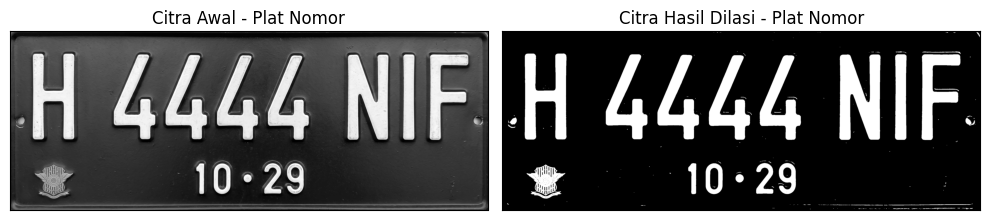

SED = Circle 3 - Noisy Text


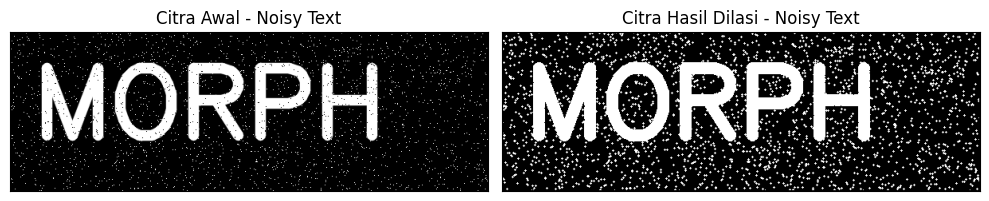

SED = Circle 5 - Plat Nomor


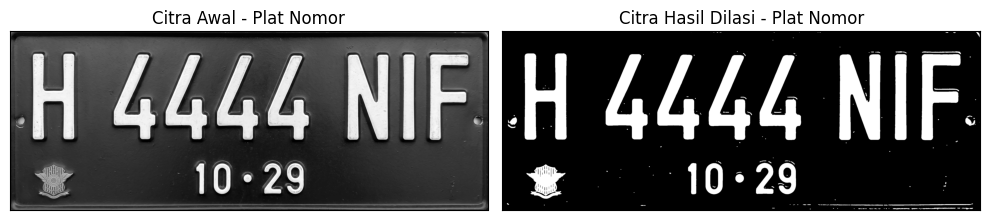

SED = Circle 5 - Noisy Text


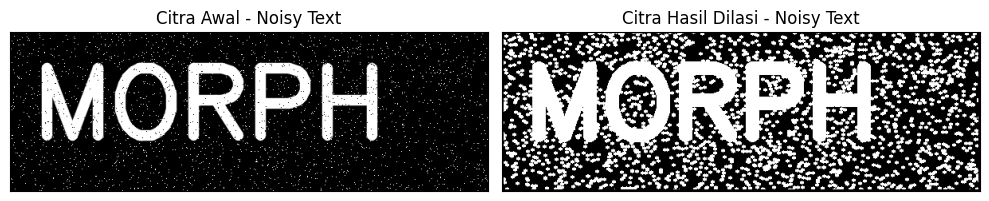

In [13]:
#Dilasi Circular SED

def dilasi_citra(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)

  #Generate structure element dilasi (SED)
  SED= cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(w,w))
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

for circle_size in [3, 5]:
  for img_path, img_name in IMAGES:
    print(f'SED = Circle {circle_size} - {img_name}')
    img_d= cv2.imread(img_path,0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    imgD = dilasi_citra(thresh,circle_size)

    plt.figure(figsize=(10,4))
    plt.subplot(121),plt.imshow(img_d,cmap = 'gray')
    plt.title(f'Citra Awal - {img_name}'), plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(imgD,cmap = 'gray')
    plt.title(f'Citra Hasil Dilasi - {img_name}'), plt.xticks([]), plt.yticks([])
    plt.tight_layout()
    plt.show()

## Langkah 11 - Erosi dengan SE Rectangle 3x5 dan 5x7
Buatlah program implementasi operasi erosi dengan Structuring Element berbentuk Rectangle 3 x 5 dan 5 x 7.

SE = Rectangle 3x5 - Plat Nomor


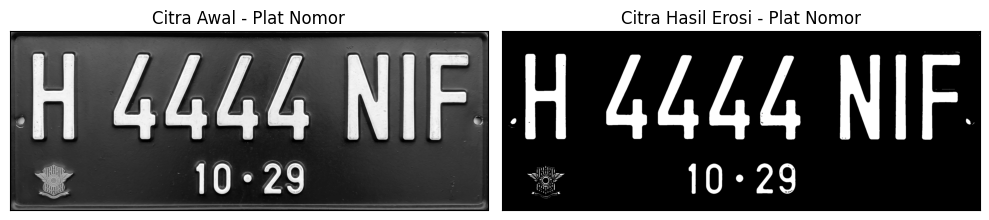

SE = Rectangle 3x5 - Noisy Text


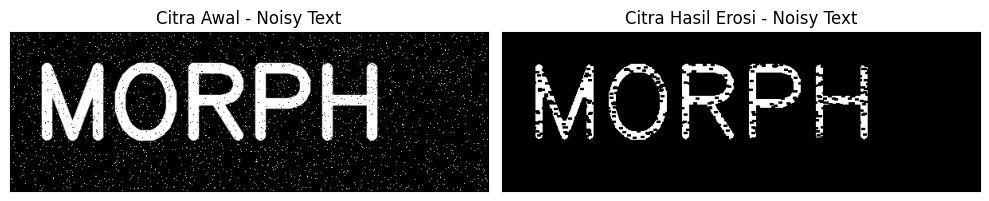

SE = Rectangle 5x7 - Plat Nomor


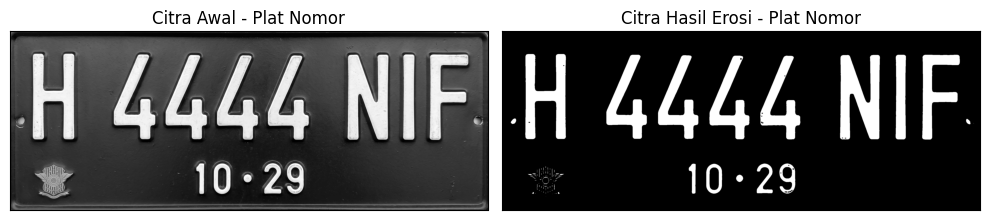

SE = Rectangle 5x7 - Noisy Text


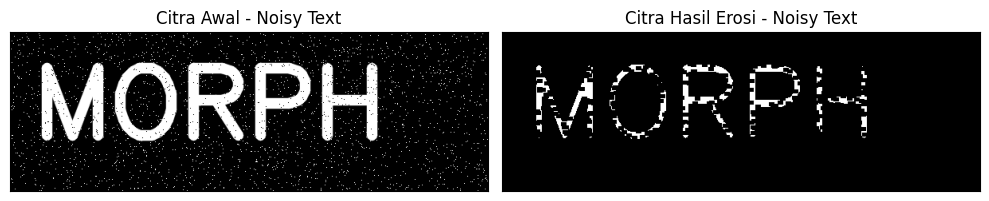

In [14]:
#Erosi Rectangle SE

def erosi_citra(F,p,l):
  #size image
  m,n= F.shape

  #Generate structure element erosi (SE)
  SE = cv2.getStructuringElement(cv2.MORPH_RECT,(p,l)) #SE persegi panjang
  constant1= (l-1)//2
  constant2= (p-1)//2
  # print(SE)
  imgE= np.zeros((m,n), dtype=np.uint8)

  #Proses Erosi
  for i in range(constant1, m-constant1):
    for j in range(constant2,n-constant2):
      temp= F[i-constant1:i+constant1+1, j-constant2:j+constant2+1]
      product= temp*SE
      imgE[i,j]= np.min(product)

  return imgE

rect_sizes = [(5, 3, '3x5'), (7, 5, '5x7')]
for p_val, l_val, size_label in rect_sizes:
  for img_path, img_name in IMAGES:
    print(f'SE = Rectangle {size_label} - {img_name}')
    img_e= cv2.imread(img_path,0)
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    imgE = erosi_citra(thresh1,p_val,l_val)

    plt.figure(figsize=(10,4))
    plt.subplot(121),plt.imshow(img_e,cmap = 'gray')
    plt.title(f'Citra Awal - {img_name}'), plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(imgE,cmap = 'gray')
    plt.title(f'Citra Hasil Erosi - {img_name}'), plt.xticks([]), plt.yticks([])
    plt.tight_layout()
    plt.show()

## Langkah 12 - Erosi dengan SE Line Vertikal 3 dan 5
Buatlah program implementasi operasi erosi dengan Structuring Element berbentuk Line Vertikal 3 dan 5.

SE = Line Vertikal 3 - Plat Nomor


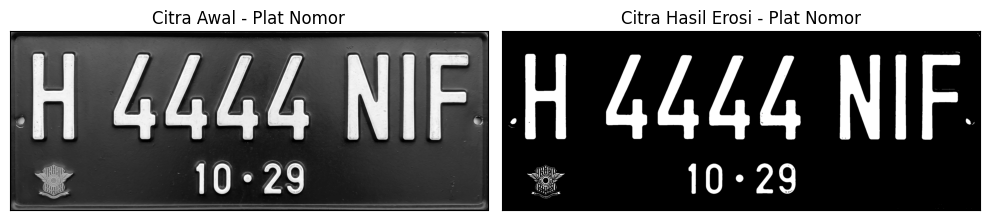

SE = Line Vertikal 3 - Noisy Text


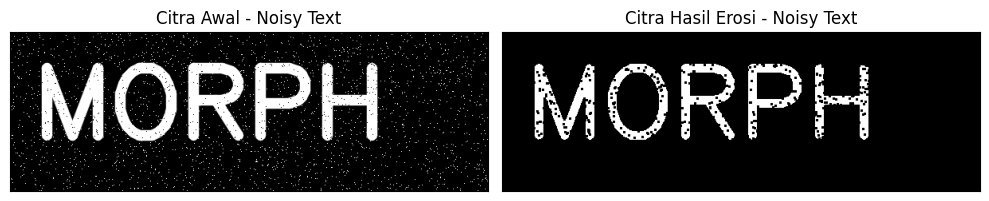

SE = Line Vertikal 5 - Plat Nomor


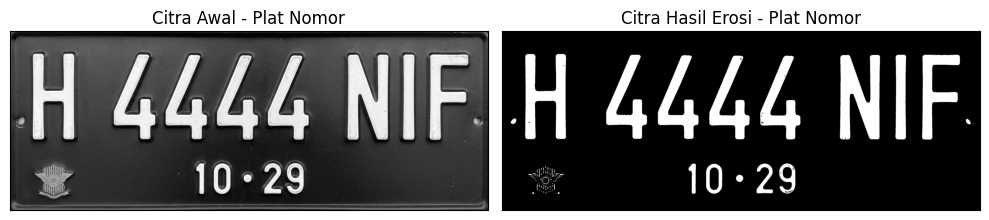

SE = Line Vertikal 5 - Noisy Text


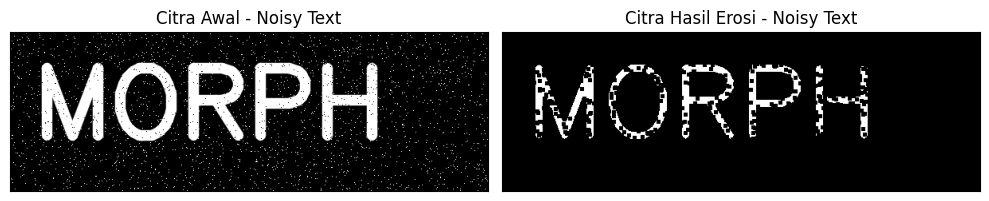

In [15]:
#Erosi Line Vertikal SE

def erosi_citra(F,k):
  #size image
  m,n= F.shape

  #Generate structure element erosi (SE)
  SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(1,k)) #SE line vertikal
  constant= (k-1)//2

  imgE= np.zeros((m,n), dtype=np.uint8)

  #Proses Erosi
  for i in range(constant, m-constant):
    for j in range(constant,n-constant):
      temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
      product= temp*SE
      imgE[i,j]= np.min(product)

  return imgE

for k_val in [3, 5]:
  for img_path, img_name in IMAGES:
    print(f'SE = Line Vertikal {k_val} - {img_name}')
    img_e= cv2.imread(img_path,0)
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    imgE = erosi_citra(thresh1,k_val)

    plt.figure(figsize=(10,4))
    plt.subplot(121),plt.imshow(img_e,cmap = 'gray')
    plt.title(f'Citra Awal - {img_name}'), plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(imgE,cmap = 'gray')
    plt.title(f'Citra Hasil Erosi - {img_name}'), plt.xticks([]), plt.yticks([])
    plt.tight_layout()
    plt.show()

## Langkah 13 - Transformasi Top-Hat
Buatlah program transformasi Top-hat dengan structuring element 3 × 3, lalu tampilkan citra asal dan hasilnya secara berdampingan.

=== Top-Hat - Plat Nomor ===


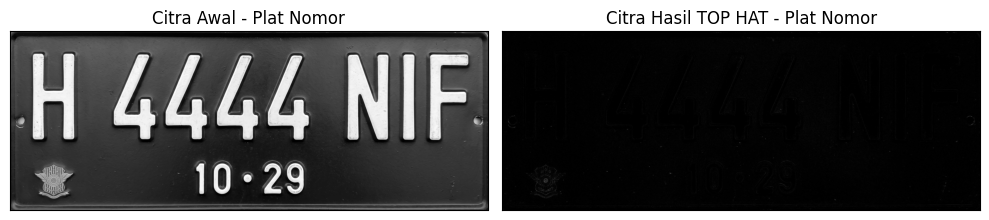

=== Top-Hat - Noisy Text ===


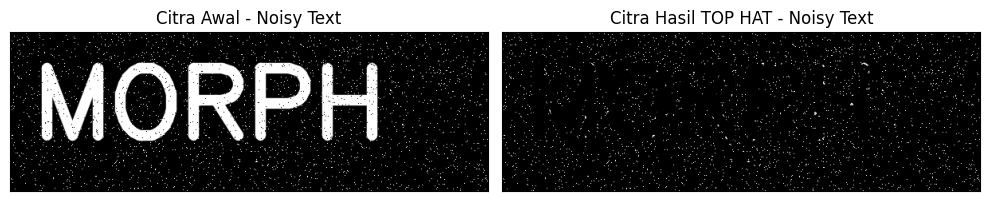

In [16]:
# Getting the kernel to be used in Top-Hat
filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT,
                filterSize)

for img_path, img_name in IMAGES:
  print(f'=== Top-Hat - {img_name} ===')
  # Reading the image
  img = cv2.imread(img_path)
  img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

  # Applying the Top-Hat operation
  tophat_img = cv2.morphologyEx(img,
                cv2.MORPH_TOPHAT,
                kernel)

  plt.figure(figsize=(10,4))
  plt.subplot(121),plt.imshow(img,cmap = 'gray')
  plt.title(f'Citra Awal - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(tophat_img,cmap = 'gray')
  plt.title(f'Citra Hasil TOP HAT - {img_name}'), plt.xticks([]), plt.yticks([])
  plt.tight_layout()
  plt.show()

## Langkah 14 - Transformasi Black-Hat
Buatlah program transformasi Black-hat dengan structuring element 3 × 3. Ingat, Black-hat adalah hasil closing dikurangi citra asal.

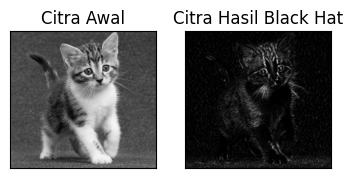

In [17]:
filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image named 'input.jpg'
img = cv2.imread('/content/drive/MyDrive/Uni/Internal/Semester 5/PCdVK/kitten01 (1).jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Black-Hat operation
#tophat_img = cv2.morphologyEx(img,cv2.MORPH_BLACKHAT, kernel)
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)
#cv2.imshow("original", input_image)
#cv2.imshow("tophat", tophat_img)
#cv2.waitKey(5000)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(blackhat,cmap = 'gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

## Langkah 15 - Skeleton pada Citra Biner
Buatlah program skeleton pada citra biner, lalu tampilkan citra biner dan rangkanya secara berdampingan.

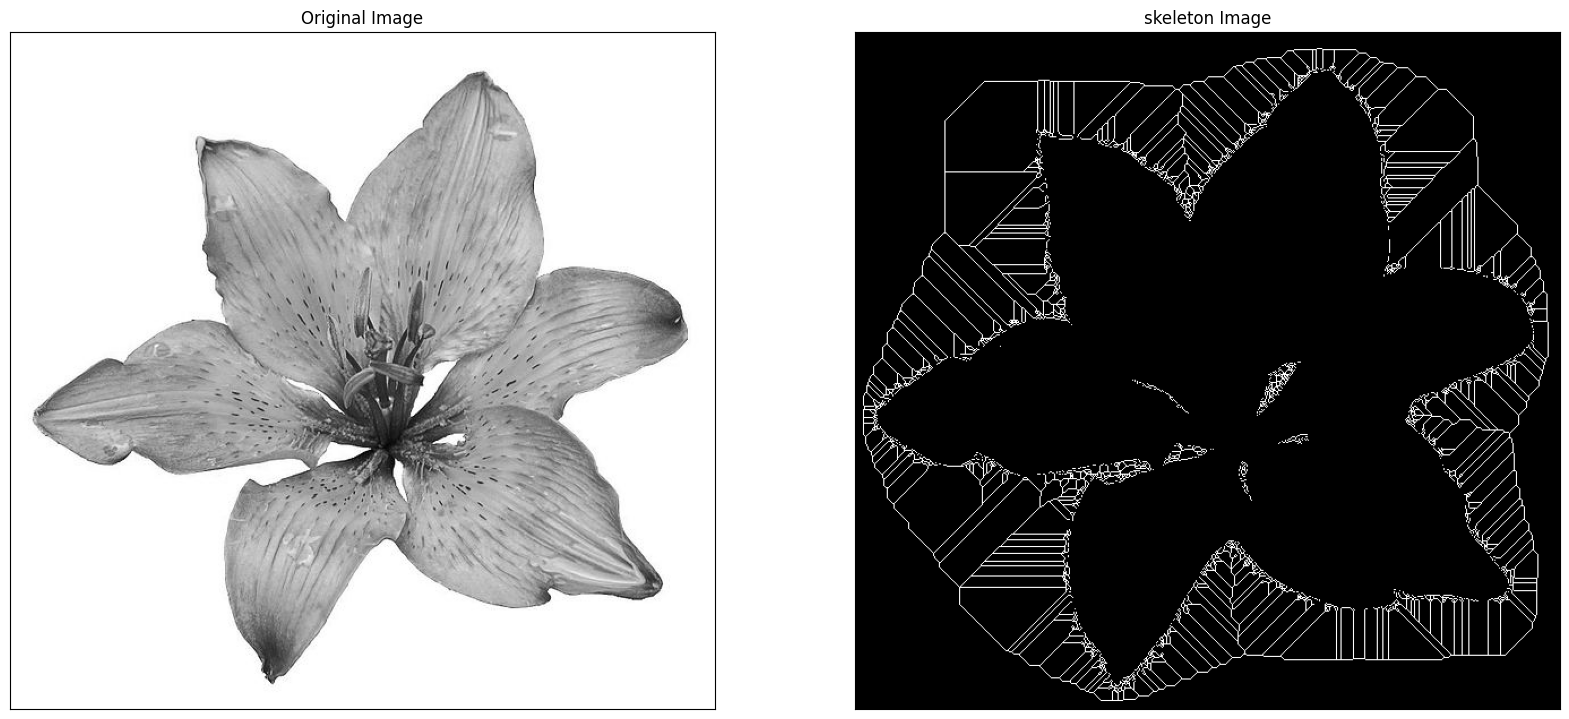

In [18]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = cv.imread('/content/drive/MyDrive/Uni/Internal/Semester 5/PCdVK/lily.jpg',0)

binary = img > filters.threshold_triangle(img)

# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# skeletonize image
skeleton = skeletonize(binary_cp)

# print images
plt.figure(figsize=(20,20))

plt.subplot(121),plt.imshow(img,cmap = 'gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])

plt.subplot(122),plt.imshow(skeleton,cmap = 'gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])

plt.savefig("binary and bin_skeleton.png")
plt.show()

## Langkah 16 - Skeleton pada Citra Inversi
Buatlah program skeleton pada citra hasil inversi, lalu bandingkan hasilnya dengan langkah sebelumnya.

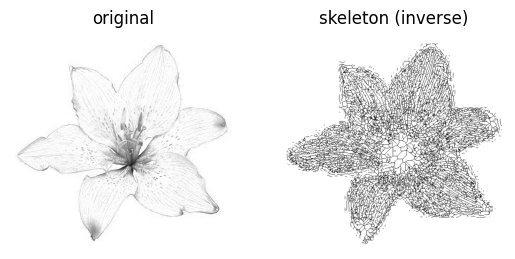

In [19]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = io.imread('/content/drive/MyDrive/Uni/Internal/Semester 5/PCdVK/lily.jpg')[..., 0]

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)

# skeletonize image
skeleton = skeletonize(binary)

# print images
fig, ax = plt.subplots(1, 2)

ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()

plt.show()

## Langkah 17 - Thinning
Buatlah program thinning memakai morphology.thin(), lalu bandingkan hasilnya dengan skeleton pada langkah 15.

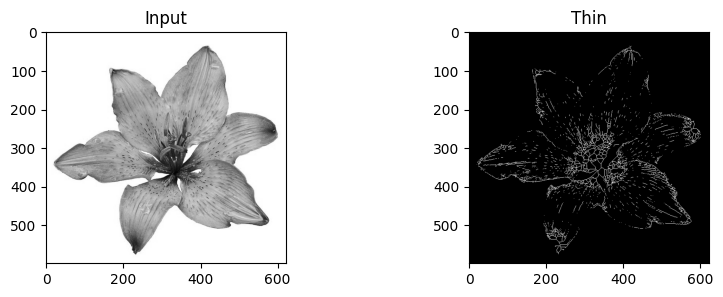

In [20]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/Uni/Internal/Semester 5/PCdVK/lily.jpg')))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

plt.savefig('/tmp/char_out.png')
plt.show()